# Junk Food Binary Classification with CLIP using ViT

This notebook implements a **CLIP** model (zero-shot) for binary image classification (`junk-food-ad` vs `non-junk-food-ad`) using the **leakage-aware binary dataset** (`binary-dataset.zip`, folders `ad` / `non_ad` + `groups.csv`) stored in Google Drive.

The train/val/test split is **group-aware**: all frames of the same ad creative or source video stay in the same split, so near-duplicate frames cannot leak from train into validation/test.

## Before you start

Make sure you have access to GPU. In case of any problems, navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, click `Save` and try again.

In [1]:
!nvidia-smi

Mon Nov 23 03:57:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
HOME = os.getcwd()
print("HOME:", HOME)
!mkdir -p {HOME}/datasets
%cd {HOME}/datasets

HOME: /content
/content/datasets


## Install packages using pip


In [3]:
!pip install open-clip-torch==3.2.0 pillow==11.3.0 torch==2.9.0 torchvision==0.24.0

  Using cached open_clip_torch-3.2.0-py3-none-any.whl.metadata (32 kB)
  Using cached torch-2.9.0-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (30 kB)
  Using cached torchvision-0.24.0-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (5.9 kB)
  Using cached ftfy-6.3.1-py3-none-any.whl.metadata (7.3 kB)
  Using cached nvidia_cuda_nvrtc_cu12-12.8.93-py3-none-manylinux2010_x86_64.manylinux_2_12_x86_64.whl.metadata (1.7 kB)
  Using cached nvidia_cuda_runtime_cu12-12.8.90-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (1.7 kB)
  Using cached nvidia_cuda_cupti_cu12-12.8.90-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (1.7 kB)
  Using cached nvidia_cudnn_cu12-9.10.2.21-py3-none-manylinux_2_27_x86_64.whl.metadata (1.8 kB)
  Using cached nvidia_cublas_cu12-12.8.4.1-py3-none-manylinux_2_27_x86_64.whl.metadata (1.7 kB)
  Using cached nvidia_cufft_cu12-11.3.3.83-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (1.7 kB)
  Using cached nvidia_cur

## Load dataset from Google Drive

Mount your Google Drive and add a Colab secret named `BINARY_DATASET_ZIP_PATH` (Secrets panel - the key icon in the left sidebar) pointing to `binary-dataset.zip` in Drive (absolute, e.g. `/content/drive/MyDrive/datasets/binary-dataset.zip`, or relative to `/content/drive`, e.g. `MyDrive/datasets/binary-dataset.zip`).

The zip (produced by `unhealthy-dataset-generator`) contains `ad/` (junk food ads), `non_ad/` (everything else) and `groups.csv`, which assigns every frame to a **group**: frames of the same ad creative (`ad_XXXX`) or of the same source video (`non_ad_<video>`). `groups.csv` may also list frames that were capped/rebalanced out of the zip; those rows are ignored. The notebook checks that every image has exactly one group and that the CSV label matches its folder.

Frames of the same ad creative or the same source video are near-duplicates, so a random per-image split would leak them between train and evaluation. We therefore assign **whole groups** to **train/val/test** (target 70/15/15 of the frames of each class, fixed seed 42): no group appears in more than one split. Shares are approximate because groups have different sizes. The positive class is `junk-food-ad` (from the `ad/` folder) and the negative class is `non-junk-food-ad` (from the `non_ad/` folder).

CLIP is zero-shot, so only val (prompt selection, called `valid` below) and test (final evaluation) are used.

In [4]:
import os
import shutil
import zipfile
import numpy as np
import pandas as pd
from google.colab import drive, userdata

drive.mount('/content/drive')

# Path to binary-dataset.zip in your Google Drive. Add BINARY_DATASET_ZIP_PATH in Colab's
# "Secrets" panel (key icon in the left sidebar), e.g.
# /content/drive/MyDrive/Colab Notebooks/Tesis/datasets/binary-dataset.zip
_zip_secret = userdata.get('BINARY_DATASET_ZIP_PATH').strip()
DATASET_ZIP_PATH = (_zip_secret if _zip_secret.startswith('/content/')
                    else os.path.join('/content/drive', _zip_secret.lstrip('/')))
if not os.path.isfile(DATASET_ZIP_PATH):
    raise FileNotFoundError(f"Dataset zip not found: {DATASET_ZIP_PATH}")

# Copy the zip to local Colab storage and extract it there (much faster than reading from Drive).
# Always start from a clean folder so a previous/partial extraction can't leave stale files behind.
LOCAL_ZIP_PATH = "/content/binary-dataset.zip"
EXTRACT_ROOT = "/content/binary_dataset"
shutil.copy(DATASET_ZIP_PATH, LOCAL_ZIP_PATH)
if os.path.exists(EXTRACT_ROOT):
    shutil.rmtree(EXTRACT_ROOT)
with zipfile.ZipFile(LOCAL_ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_ROOT)

# Locate the folder that contains ad/, non_ad/ and groups.csv
DATASET_ROOT = None
for current_dir, subdirs, file_names in os.walk(EXTRACT_ROOT):
    if "ad" in subdirs and "non_ad" in subdirs and "groups.csv" in file_names:
        DATASET_ROOT = current_dir
        break
if DATASET_ROOT is None:
    raise FileNotFoundError("Could not find 'ad/', 'non_ad/' and 'groups.csv' inside the extracted dataset.")
print("Dataset folder:", DATASET_ROOT)

# Map source folders to binary class names. The positive class maps to index 0.
CLASS_FOLDERS = {
    "ad": "junk-food-ad",          # positive class
    "non_ad": "non-junk-food-ad",  # negative class
}
POSITIVE_CLASS = "junk-food-ad"
NEGATIVE_CLASS = "non-junk-food-ad"
IMG_EXTS = (".jpg", ".jpeg", ".png")

# Images actually present in the zip
disk_rows = []
for folder, class_name in CLASS_FOLDERS.items():
    folder_path = os.path.join(DATASET_ROOT, folder)
    for file_name in sorted(os.listdir(folder_path)):
        if file_name.lower().endswith(IMG_EXTS):
            disk_rows.append({"image_name": file_name, "folder": folder, "class_name": class_name,
                              "path": os.path.join(folder_path, file_name)})
disk_df = pd.DataFrame(disk_rows)
duplicated = disk_df[disk_df["image_name"].duplicated(keep=False)]
if not duplicated.empty:
    raise ValueError(f"Image names repeated across folders: {duplicated['image_name'].unique()[:10].tolist()}")

groups_df = pd.read_csv(os.path.join(DATASET_ROOT, "groups.csv"), dtype=str, encoding="utf-8-sig")
missing_cols = {"image_name", "label", "group"} - set(groups_df.columns)
if missing_cols:
    raise ValueError(f"groups.csv is missing columns: {sorted(missing_cols)}")
groups_df["image_name"] = groups_df["image_name"].str.strip()
groups_df = groups_df[groups_df["image_name"].isin(set(disk_df["image_name"]))]
if groups_df["image_name"].duplicated().any():
    raise ValueError("groups.csv has duplicated rows for images in the zip: "
                     f"{groups_df.loc[groups_df['image_name'].duplicated(), 'image_name'].tolist()[:10]}")

dataset_df = disk_df.merge(groups_df[["image_name", "label", "group"]], on="image_name", how="left")
no_row = dataset_df[dataset_df["group"].isna() | (dataset_df["group"].str.strip() == "")]
if not no_row.empty:
    raise ValueError(f"{len(no_row)} images have no group in groups.csv, e.g. {no_row['image_name'].tolist()[:10]}")
mismatch = dataset_df[dataset_df["label"].str.strip() != dataset_df["folder"]]
if not mismatch.empty:
    raise ValueError(f"{len(mismatch)} images have a groups.csv label different from their folder, "
                     f"e.g. {mismatch[['image_name', 'label', 'folder']].head().to_dict('records')}")
dataset_df["group"] = dataset_df["group"].str.strip()
dataset_df = dataset_df.drop(columns="label")

print(f"Images: {len(dataset_df)} | groups: {dataset_df['group'].nunique()}")
print(dataset_df.groupby("class_name").agg(images=("image_name", "size"), groups=("group", "nunique")).to_string())


SEED = 42
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
# When a class has fewer groups than splits, its groups go to the splits in this order:
# 1 group -> train; 2 groups -> train + test (so the class is still evaluated); >= 3 -> all splits.
SUPPORT_ORDER = ("train", "test", "val")


def stratified_group_split(frame, label_col, group_col="group", fractions=SPLIT_FRACTIONS,
                           support_order=SUPPORT_ORDER, seed=SEED):
    """Assign whole groups to splits while keeping the per-class frame shares close to `fractions`.

    Groups (same creative / same source video) are atomic, so near-identical frames never
    cross splits. A group may contain frames of several classes; it is described by its
    per-class frame counts. Classes are processed from the one with the fewest groups to
    the one with the most; each carrier group (largest first, seeded order on ties) goes to
    the split with the largest remaining deficit for that class, then for total frames.
    A repair pass then guarantees every class has at least one group in the splits given by
    `support_order` (moving the smallest donor group that its own split can spare).

    Returns a dict group -> split name.
    """
    splits = list(fractions)
    counts = pd.crosstab(frame[group_col], frame[label_col])
    order = counts.index.to_numpy().copy()
    np.random.default_rng(seed).shuffle(order)
    counts = counts.loc[order]
    classes = list(counts.columns)
    sizes = counts.sum(axis=1)

    class_target = {s: counts.sum(axis=0) * f for s, f in fractions.items()}
    frame_target = {s: sizes.sum() * f for s, f in fractions.items()}
    filled = {s: pd.Series(0.0, index=classes) for s in splits}
    assignment = {}

    n_carriers = (counts > 0).sum(axis=0).sort_values(kind="stable")
    for cls in n_carriers.index:
        carriers = [g for g in counts.index if g not in assignment and counts.loc[g, cls] > 0]
        carriers.sort(key=lambda g: -counts.loc[g, cls])
        for g in carriers:
            split = max(splits, key=lambda s: (class_target[s][cls] - filled[s][cls],
                                               frame_target[s] - filled[s].sum()))
            assignment[g] = split
            filled[split] += counts.loc[g]

    def required(cls):
        return [s for s in support_order if s in splits][:min(int(n_carriers[cls]), len(splits))]

    def carriers_in(cls, split):
        return sum(1 for g, s in assignment.items() if s == split and counts.loc[g, cls] > 0)

    def can_leave(g, split):
        return all(carriers_in(c, split) > 1 or split not in required(c)
                   for c in classes if counts.loc[g, c] > 0)

    changed = True
    while changed:
        changed = False
        for cls in n_carriers.index:
            for split in required(cls):
                if carriers_in(cls, split):
                    continue
                donors = [g for g, s in assignment.items()
                          if s != split and counts.loc[g, cls] > 0 and can_leave(g, s)]
                if donors:
                    assignment[min(donors, key=lambda g: sizes[g])] = split
                    changed = True

    for cls in n_carriers.index:
        missing = [s for s in required(cls) if not carriers_in(cls, s)]
        if missing:
            print(f"  NOTE: class {cls!r} has no group in {missing} (its groups cannot be moved)")
        if n_carriers[cls] < len(splits):
            present = [s for s in splits if carriers_in(cls, s)]
            print(f"  NOTE: class {cls!r} has only {int(n_carriers[cls])} group(s); present in {present}")
    return assignment


def assert_no_group_leakage(frame, group_col="group", split_col="split"):
    splits_per_group = frame.groupby(group_col)[split_col].nunique()
    leaked = splits_per_group[splits_per_group > 1]
    assert leaked.empty, f"LEAKAGE: groups in more than one split: {list(leaked.index)}"


def print_split_summary(frame, label_col, group_col="group", split_col="split"):
    split_names = [s for s in SPLIT_FRACTIONS if s in set(frame[split_col])]
    frames = pd.crosstab(frame[label_col], frame[split_col]).reindex(columns=split_names, fill_value=0)
    groups = (frame.groupby([label_col, split_col])[group_col].nunique().unstack(fill_value=0)
              .reindex(index=frames.index, columns=split_names, fill_value=0))
    table = frames.astype(str) + " (" + groups.astype(str) + " gr)"
    total_groups = frame.groupby(label_col)[group_col].nunique().reindex(frames.index)
    table["total"] = frames.sum(axis=1).astype(str) + " (" + total_groups.astype(str) + " gr)"
    print("Frames (groups) per class and split:")
    print(table.to_string())
    totals = frames.sum(axis=0)
    print("\nFrames per split: " + ", ".join(
        f"{s}={int(totals[s])} ({totals[s] / totals.sum():.1%}, "
        f"{frame.loc[frame[split_col] == s, group_col].nunique()} groups)"
        for s in split_names))


group_to_split = stratified_group_split(dataset_df, label_col="class_name")
dataset_df["split"] = dataset_df["group"].map(group_to_split)
assert dataset_df["split"].notna().all()
assert_no_group_leakage(dataset_df)
# Interleave classes inside every split (reproducible)
dataset_df = dataset_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
print_split_summary(dataset_df, label_col="class_name")

# CLIP code below uses the split names train/valid/test and (path, class_name) samples.
SPLIT_RATIOS = {"train": SPLIT_FRACTIONS["train"], "valid": SPLIT_FRACTIONS["val"], "test": SPLIT_FRACTIONS["test"]}
splits_data = {
    name: list(dataset_df.loc[dataset_df["split"] == source, ["path", "class_name"]].itertuples(index=False, name=None))
    for name, source in (("train", "train"), ("valid", "val"), ("test", "test"))
}

os.makedirs(os.path.join(HOME, "runs"), exist_ok=True)
SPLIT_MANIFEST_PATH = os.path.join(HOME, "runs", "clip_binary_split_manifest.csv")
dataset_df.assign(path=dataset_df["path"].map(lambda p: os.path.relpath(p, DATASET_ROOT)))[
    ["path", "class_name", "group", "split"]].to_csv(SPLIT_MANIFEST_PATH, index=False)
print("\nSplit manifest:", SPLIT_MANIFEST_PATH)

print("=" * 50)
print("DATASET SUMMARY")
print("=" * 50)
for split_name, samples in splits_data.items():
    print(f"\n{split_name.upper()}: {len(samples)} images")
    for class_name in CLASS_FOLDERS.values():
        count = sum(1 for _, c in samples if c == class_name)
        print(f"  - {class_name}: {count}")

Mounted at /content/drive
Dataset folder: /content/binary_dataset
Images: 5272 | groups: 112
                  images  groups
class_name                      
junk-food-ad        2636      86
non-junk-food-ad    2636      26
Frames (groups) per class and split:
split                    train          val         test         total
class_name                                                            
junk-food-ad      1844 (48 gr)  397 (19 gr)  395 (19 gr)  2636 (86 gr)
non-junk-food-ad  1863 (18 gr)   385 (4 gr)   388 (4 gr)  2636 (26 gr)

Frames per split: train=3707 (70.3%, 66 groups), val=782 (14.8%, 23 groups), test=783 (14.9%, 23 groups)

Split manifest: /content/runs/clip_binary_split_manifest.csv
DATASET SUMMARY

TRAIN: 3707 images
  - junk-food-ad: 1844
  - non-junk-food-ad: 1863

VALID: 782 images
  - junk-food-ad: 397
  - non-junk-food-ad: 385

TEST: 783 images
  - junk-food-ad: 395
  - non-junk-food-ad: 388


In [5]:
%cd {HOME}

/content


## Prepare OpenCLIP model

In [6]:
import time
import torch
import open_clip
from PIL import Image

# Setup
device = "cuda" if torch.cuda.is_available() else "cpu"
NEGATIVE_CLASS = CLASS_FOLDERS["non_ad"]
torch.manual_seed(SEED)


def timed_now():
    if device == "cuda":
        torch.cuda.synchronize()
    return time.perf_counter()


model_setup_start = timed_now()
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-16",
    pretrained="laion2b_s34b_b88k"
)
tokenizer = open_clip.get_tokenizer("ViT-B-16")
model = model.to(device)
model.eval()
model_setup_seconds = timed_now() - model_setup_start
print("Device:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")
print(f"Model setup (including weight loading/download): {model_setup_seconds:.2f} s")


PROMPT_TEMPLATES = [
    "a photo of {}",
    "a picture of {}",
    "an image containing {}",
    "a close-up photo of {}",
    "an ad containing {}"
]


def encode_class_prompts(classes):
    with torch.no_grad():
        text_features = []

        for cls in classes:
            prompts = [t.format(cls) for t in PROMPT_TEMPLATES]
            tokens = tokenizer(prompts).to(device)

            embeddings = model.encode_text(tokens)
            embeddings /= embeddings.norm(dim=-1, keepdim=True)

            class_embedding = embeddings.mean(dim=0)
            class_embedding /= class_embedding.norm()

            text_features.append(class_embedding)

        return torch.stack(text_features)


def classify_images_with_clip(dataset_part, classes):
    samples = splits_data[dataset_part]
    image_paths = [path for path, _ in samples]
    ground_truth = {path: class_name for path, class_name in samples}
    text_features = encode_class_prompts(classes)

    results = {}

    for image_path in image_paths:
        try:
            with Image.open(image_path) as source_image:
                image = source_image.convert("RGB")
            image_tensor = preprocess(image).unsqueeze(0).to(device)

            with torch.no_grad():
                image_features = model.encode_image(image_tensor)
                image_features /= image_features.norm(dim=-1, keepdim=True)

                similarities = (image_features @ text_features.T).squeeze(0)

            # Binary classification: pick the class with highest similarity
            predicted_idx = similarities.argmax().item()
            predicted_class = classes[predicted_idx]

            results[image_path] = predicted_class

        except FileNotFoundError as exc:
            raise FileNotFoundError(f"Image file not found: {image_path}. Cannot continue processing.") from exc

    return results, ground_truth, image_paths

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

Device: Tesla T4
Model setup (including weight loading/download): 12.20 s


## Metrics

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def evaluate_predictions(image_paths, ground_truth, results, class_true, class_false):
  if any(ground_truth[path] not in (POSITIVE_CLASS, NEGATIVE_CLASS) for path in image_paths):
      raise ValueError("Unknown ground-truth class.")
  if any(results[path] not in (class_true, class_false) for path in image_paths):
      raise ValueError("Unknown predicted class.")
  y_true = [1 if ground_truth[image_path] == POSITIVE_CLASS else 0 for image_path in image_paths]
  y_pred = [1 if results[image_path] == class_true else 0 for image_path in image_paths]

  # No need for pos_label because we are already converting everything above with 0 and 1.
  return {
      'accuracy': accuracy_score(y_true, y_pred),
      'precision': precision_score(y_true, y_pred, zero_division=0),
      'recall': recall_score(y_true, y_pred, zero_division=0),
      'f1_score': f1_score(y_true, y_pred, zero_division=0),
      'confusion_matrix': confusion_matrix(y_true, y_pred, labels=[0, 1])
  }

## Let's try some combinations in the valid set

We compare 145 prompt pairs using the same five templates, without updating CLIP weights. Rank by positive-class F1 on validation only; ties retain the original candidate order. Freeze the top ten and designate validation rank 1 as the primary configuration before evaluating test. Timings include text/image encoding, image loading, preprocessing and metrics, but exclude installation, dataset extraction, model setup and plots.

In [8]:
class_variants = [
  ["junk food", "something else"],
  ["junk food advertisements", "not junk food advertisements"],
  ["unhealthy food", "healthy food"],
  ["processed food", "whole food"],
  ["high-calorie food", "nutritious food"],
  ["unhealthy food advertisement", "healthy food advertisement"],
  ["fast food advertisement", "non-fast food advertisement"],
  ["junk food advertisement", "non-food advertisement"],
  ["junk food marketing", "non-food marketing"],
  ["unhealthy food promotion", "healthy food promotion"],
  ["food advertisement for unhealthy products", "other advertisements"],
  ["image of junk food being advertised", "image not advertising junk food"],
  ["advertisement showing unhealthy food", "advertisement not showing food"],
  ["promotional image of fast food", "non-promotional image"],
  ["mostly unhealthy food advertisement", "other advertisement"],
  ["unhealthy snack or fast food ad", "non-unhealthy food ad"],
  ["advertisement dominated by junk food", "advertisement without junk food"],
  ["sugary or fatty food", "nutritious food"],
  ["high-sugar high-fat food", "low-sugar low-fat food"],
  ["ultra-processed food", "minimally processed food"],
  ["fried food", "non-fried food"],
  ["candy or fast food", "fruits or vegetables"],
  ["soda or dessert", "water or produce"],
  ["commercial for unhealthy food", "commercial for healthy food"],
  ["marketing for junk food", "marketing for whole foods"],
  [
    "advertisement promoting unhealthy eating",
    "advertisement promoting healthy eating"
  ],
  [
    "promotional content for fast food",
    "promotional content for nutritious food"
  ],
  ["brand advertisement for junk food", "brand advertisement for healthy food"],
  ["fast food or candy", "fresh food"],
  ["chips or soda", "natural food"],
  ["burgers or pizza", "salad or grain"],
  ["dessert or fried food", "vegetable or fruit"],
  ["packaged snacks", "whole ingredients"],
  ["low-nutrition food", "high-nutrition food"],
  ["empty calorie food", "nutrient-dense food"],
  [
    "food high in added sugar or saturated fat",
    "food low in added sugar or saturated fat"
  ],
  ["nutritionally poor food", "nutritionally rich food"],
  ["food that contributes to poor health", "food that supports good health"],
  ["obesogenic food", "health-promoting food"],
  [
    "image featuring unhealthy food products",
    "image not featuring unhealthy food products"
  ],
  ["photo of junk food being marketed", "photo not of junk food"],
  ["picture showing fast food promotion", "picture not showing fast food"],
  ["visual of unhealthy food advertisement", "visual of other content"],
  ["ad for junk food", "ad for something else"],
  ["junk food ad", "not a junk food ad"],
  ["unhealthy food ad", "other ad"],
  ["fast food ad", "other ad"],
  [
    "advertisement image that primarily features or promotes unhealthy food products",
    "advertisement image that does not primarily feature unhealthy food"
  ],
  [
    "marketing material showing junk food or fast food",
    "marketing material not showing junk food or fast food"
  ],
  [
    "promotional imagery for high-calorie low-nutrient food",
    "promotional imagery for other products"
  ],
  ["fast food or processed snacks", "whole foods or other content"],
  ["sugary beverages or candy", "non-sugary products"],
  ["deep-fried food products", "non-fried items"],
  ["calorie-dense processed food", "nutrient-rich food or other imagery"],
  ["junk food brand promotion", "other brand promotion"],
  ["unhealthy eating advertisement", "non-unhealthy eating content"],
  ["promotion of sugar-laden products", "promotion of other products"],
  [
    "marketing for high-sodium food",
    "marketing for low-sodium food or other items"
  ],
  ["ad campaign for junk food brands", "ad campaign for other brands"],
  ["processed snack food", "unprocessed food or non-food"],
  ["chocolate or candy bars", "natural foods or other products"],
  ["energy drinks or soda", "healthy beverages or other items"],
  ["packaged desserts", "fresh produce or other content"],
  ["frozen fast food products", "fresh ingredients or other imagery"],
  ["sweetened cereal", "unsweetened options or other products"],
  [
    "advertisement for sugar-sweetened beverages",
    "advertisement for other beverages or products"
  ],
  [
    "promotion featuring fried or fatty foods",
    "promotion without fried or fatty foods"
  ],
  ["image promoting processed meats", "image not promoting processed meats"],
  [
    "visual content advertising junk food",
    "visual content not advertising junk food"
  ],
  ["fast food chain marketing", "other marketing content"],
  ["unhealthy snack promotion", "healthy snack or other promotion"],
  [
    "advertisement with high-fat processed food",
    "advertisement without high-fat processed food"
  ],
  ["marketing of sugar-heavy products", "marketing of other products"],
  [
    "promotional image of unhealthy beverages",
    "promotional image of other items"
  ],
  ["junk food product showcase", "non-junk food showcase"],
  ["processed snack food", "unprocessed food"],
  ["artificially flavored food", "naturally flavored food"],
  ["deep-fried food", "baked or steamed food"],
  ["sweetened beverage", "unsweetened beverage"],
  ["food with artificial additives", "food without artificial additives"],
  ["calorie-dense food", "nutrient-dense food"],
  ["refined grain product", "whole grain product"],
  ["food with trans fats", "food without trans fats"],
  ["sodium-heavy food", "low-sodium food"],
  ["sugary cereal or snack", "whole grain or protein snack"],
  ["carbonated sugary drink", "plain water or tea"],
  ["frozen processed meal", "fresh home-cooked meal"],
  ["packaged baked goods", "fresh produce"],
  ["candy bar or chocolate", "nuts or seeds"],
  ["energy drink or soda", "natural juice or water"],
  ["junk food brand promotion", "non-junk food content"],
  ["fast food chain advertisement", "non-fast food content"],
  [
    "promotional material for processed snacks",
    "promotional material for other products"
  ],
  [
    "marketing campaign for unhealthy beverages",
    "marketing campaign for other products"
  ],
  [
    "advertisement featuring sugary products",
    "advertisement not featuring sugary products"
  ],
  ["commercial promoting fried food", "commercial not promoting fried food"],
  ["marketing for high-sodium snacks", "marketing for low-sodium foods"],
  [
    "promotional content for candy or sweets",
    "promotional content not for candy"
  ],
  [
    "advertisement for ultra-processed items",
    "advertisement for minimally processed items"
  ],
  [
    "brand marketing for fast food chains",
    "brand marketing for other products"
  ],
  ["sponsored content for junk food", "sponsored content not for junk food"],
  [
    "promotional image of packaged snacks",
    "promotional image of other products"
  ],
  [
    "advertisement showing processed desserts",
    "advertisement not showing processed desserts"
  ],
  [
    "marketing visual for sweetened beverages",
    "marketing visual for other beverages"
  ],
  [
    "commercial featuring fried snacks",
    "commercial not featuring fried snacks"
  ],
  ["unhealthy meal option", "healthy meal option"],
  ["processed convenience food", "fresh whole food"],
  ["restaurant fast food", "home-cooked food"],
  ["takeout junk food", "prepared nutritious food"],
  ["drive-through food", "sit-down restaurant food"],
  ["value meal with fried items", "balanced meal with vegetables"],
  ["combo meal with soda", "meal with water"],
  ["super-sized portion", "regular portion"],
  ["kids meal with toys", "nutritious kids meal"],
  ["limited-time unhealthy offer", "non-food limited-time offer"],
  ["greasy food", "non-greasy food"],
  ["artificial food coloring", "natural food"],
  ["heavily processed food item", "lightly processed food item"],
  ["food lacking nutritional value", "food with nutritional value"],
  ["indulgent unhealthy treat", "wholesome treat"],
  ["chemically preserved food", "naturally preserved food"],
  ["instant processed food", "freshly prepared food"],
  ["mass-produced junk food", "artisanal healthy food"],
  ["factory-made snack", "homemade snack"],
  ["shelf-stable processed food", "perishable fresh food"],
  ["advertisement for sugary snacks", "advertisement for non-sugary products"],
  [
    "advertisement for soft drinks or candy",
    "advertisement for non-food products"
  ],
  ["fast food brand promotion", "promotion for a different product"],
  [
    "junk food brand logo in an advertisement",
    "advertisement without junk food branding"
  ],
  [
    "advertisement featuring burgers fries or soda",
    "advertisement featuring non-food items"
  ],
  ["food ad showing oversized portions", "food ad showing balanced portions"],
  [
    "advertisement promoting snacks or sweets",
    "advertisement promoting non-food items"
  ],
  [
    "advertisement highlighting indulgent food",
    "advertisement highlighting healthy or non-food content"
  ],
  [
    "ad image with processed snack packaging",
    "ad image without processed food packaging"
  ],
  [
    "marketing image centered on fast food meals",
    "marketing image centered on other themes"
  ],
  [
    "advertisement encouraging junk food consumption",
    "advertisement not encouraging junk food consumption"
  ],
  [
    "visual advertisement for high-calorie snacks",
    "visual advertisement for other products"
  ],
  ["photo of a fast food meal in an ad", "photo not showing a fast food meal"],
  [
    "image of sugary drinks being promoted",
    "image not promoting sugary drinks"
  ],
  [
    "advertisement with candy soda or chips",
    "advertisement without candy soda or chips"
  ],
  [
    "advertisement for convenience food",
    "advertisement for non-convenience items"
  ],
  [
    "advertisement showing heavily processed food",
    "advertisement showing minimally processed or non-food items"
  ],
  [
    "promotional image of takeout or drive-through food",
    "promotional image not related to takeout food"
  ],
  [
    "advertisement focused on indulgent eating",
    "advertisement focused on other topics"
  ],
  [
    "food marketing associated with unhealthy diets",
    "marketing not associated with unhealthy diets"
  ]
]

results_list = []
validation_start = timed_now()
for classes in class_variants:
    results, ground_truth, image_paths = classify_images_with_clip(
        dataset_part="valid",
        classes=classes
    )
    metrics = evaluate_predictions(
        image_paths=image_paths,
        ground_truth=ground_truth,
        results=results,
        class_true=classes[0],
        class_false=classes[1],
    )
    results_list.append({
        'classes': classes,
        **metrics,
    })

validation_seconds = timed_now() - validation_start
results_list.sort(key=lambda x: x['f1_score'], reverse=True)
selected_results = results_list[:10]
best_classes = list(selected_results[0]['classes'])
print(f"Prompt selection: {len(class_variants)} pairs, {validation_seconds:.2f} s ({validation_seconds / 60:.2f} min)")
print("Primary configuration (validation rank 1):", best_classes)

print("\n" + "="*80)
print("RESULTS SORTED BY F1 SCORE (BEST FIRST)")
print("="*80)

for i, result in enumerate(results_list, 1):
    print(f"\n{i}. Classes: {result['classes']}")
    print(f"   F1 Score: {result['f1_score']:.2%}")
    print(f"   Accuracy: {result['accuracy']:.2%}")
    print(f"   Precision: {result['precision']:.2%}")
    print(f"   Recall: {result['recall']:.2%}")
    print(f"   Confusion Matrix: {result['confusion_matrix']}")
    print("-"*80)

Prompt selection: 145 pairs, 2522.95 s (42.05 min)
Primary configuration (validation rank 1): ['commercial promoting fried food', 'commercial not promoting fried food']

RESULTS SORTED BY F1 SCORE (BEST FIRST)

1. Classes: ['commercial promoting fried food', 'commercial not promoting fried food']
   F1 Score: 83.57%
   Accuracy: 82.35%
   Precision: 79.23%
   Recall: 88.41%
   Confusion Matrix: [[293  92]
 [ 46 351]]
--------------------------------------------------------------------------------

2. Classes: ['photo of a fast food meal in an ad', 'photo not showing a fast food meal']
   F1 Score: 79.51%
   Accuracy: 76.34%
   Precision: 70.95%
   Recall: 90.43%
   Confusion Matrix: [[238 147]
 [ 38 359]]
--------------------------------------------------------------------------------

3. Classes: ['visual content advertising junk food', 'visual content not advertising junk food']
   F1 Score: 77.74%
   Accuracy: 72.76%
   Precision: 66.43%
   Recall: 93.70%
   Confusion Matrix: [[197 

## Evaluate the ten frozen configurations on the test set

Keep validation order: configuration 1 is the primary result, regardless of test F1. The other nine are secondary comparisons, not candidates for further selection. Confusion matrices use rows = true labels and columns = predicted labels, both ordered [non-junk-food-ad, junk-food-ad], i.e. [[TN, FP], [FN, TP]].

Test evaluation (all ten configurations): 183.94 s
Primary configuration evaluation: 18.92 s
CLIP training: none (pretrained weights remain frozen).

TEST SET METRICS - Validation rank 1 (PRIMARY)
Classes: ['commercial promoting fried food', 'commercial not promoting fried food']
Validation F1: 83.57%
Accuracy: 79.44%
Precision: 82.87% (junk-food-ad)
Recall: 74.68% (junk-food-ad)
F1-Score: 78.56% (junk-food-ad)
Test images: 783 (negative: 388, positive: 395)
TN=327, FP=61, FN=100, TP=295
Evaluation time: 18.92 s
Confusion Matrix: [[327  61]
 [100 295]]


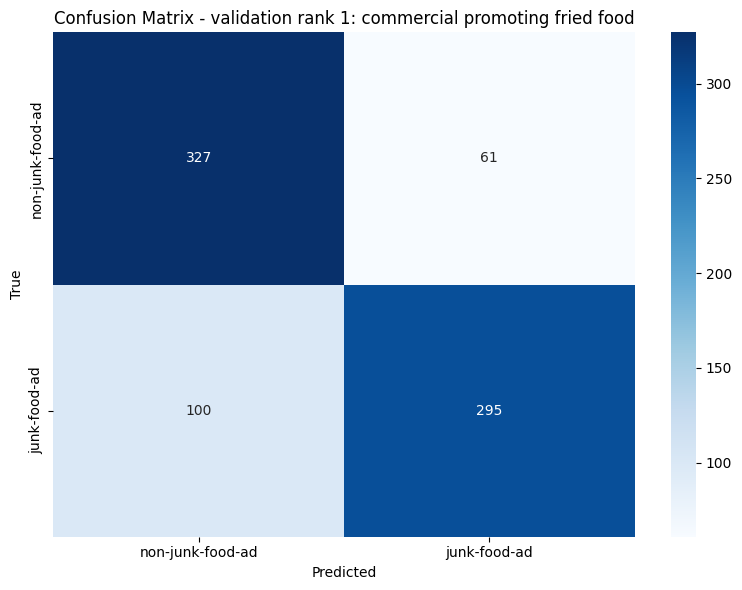


TEST SET METRICS - Validation rank 2 (SECONDARY)
Classes: ['photo of a fast food meal in an ad', 'photo not showing a fast food meal']
Validation F1: 79.51%
Accuracy: 80.46%
Precision: 78.67% (junk-food-ad)
Recall: 84.05% (junk-food-ad)
F1-Score: 81.27% (junk-food-ad)
Test images: 783 (negative: 388, positive: 395)
TN=298, FP=90, FN=63, TP=332
Evaluation time: 18.20 s
Confusion Matrix: [[298  90]
 [ 63 332]]


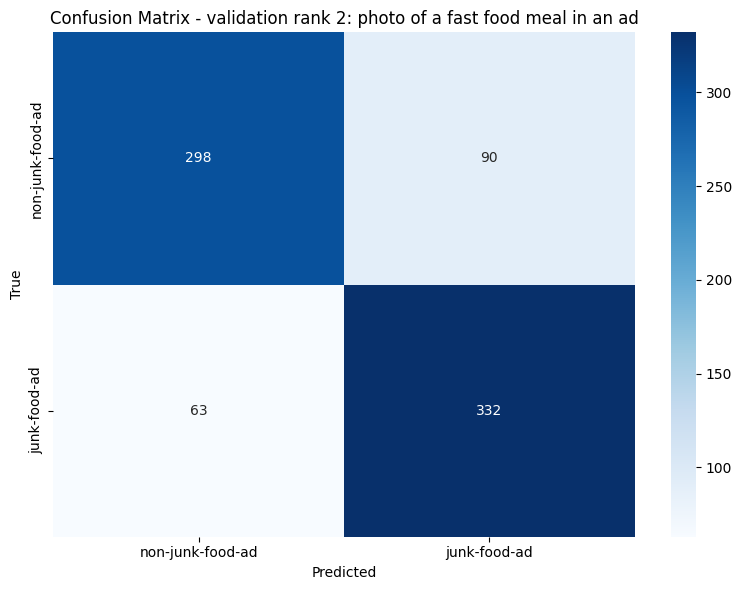


TEST SET METRICS - Validation rank 3 (SECONDARY)
Classes: ['visual content advertising junk food', 'visual content not advertising junk food']
Validation F1: 77.74%
Accuracy: 70.37%
Precision: 65.06% (junk-food-ad)
Recall: 89.11% (junk-food-ad)
F1-Score: 75.21% (junk-food-ad)
Test images: 783 (negative: 388, positive: 395)
TN=199, FP=189, FN=43, TP=352
Evaluation time: 18.21 s
Confusion Matrix: [[199 189]
 [ 43 352]]


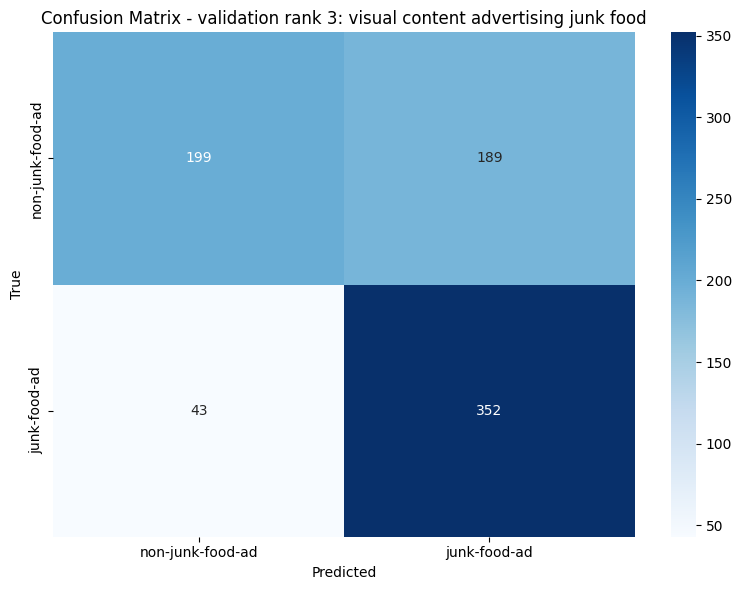


TEST SET METRICS - Validation rank 4 (SECONDARY)
Classes: ['food marketing associated with unhealthy diets', 'marketing not associated with unhealthy diets']
Validation F1: 75.61%
Accuracy: 78.80%
Precision: 92.25% (junk-food-ad)
Recall: 63.29% (junk-food-ad)
F1-Score: 75.08% (junk-food-ad)
Test images: 783 (negative: 388, positive: 395)
TN=367, FP=21, FN=145, TP=250
Evaluation time: 18.91 s
Confusion Matrix: [[367  21]
 [145 250]]


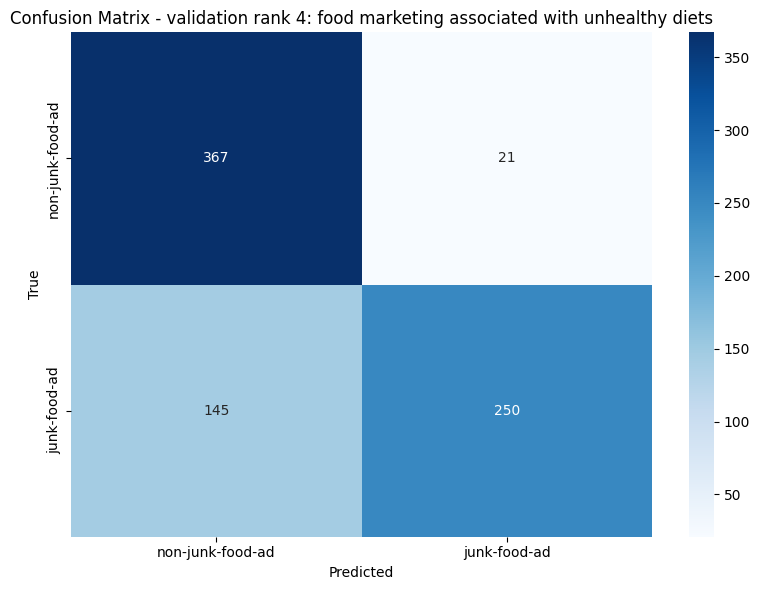


TEST SET METRICS - Validation rank 5 (SECONDARY)
Classes: ['junk food product showcase', 'non-junk food showcase']
Validation F1: 75.48%
Accuracy: 77.27%
Precision: 87.54% (junk-food-ad)
Recall: 64.05% (junk-food-ad)
F1-Score: 73.98% (junk-food-ad)
Test images: 783 (negative: 388, positive: 395)
TN=352, FP=36, FN=142, TP=253
Evaluation time: 18.11 s
Confusion Matrix: [[352  36]
 [142 253]]


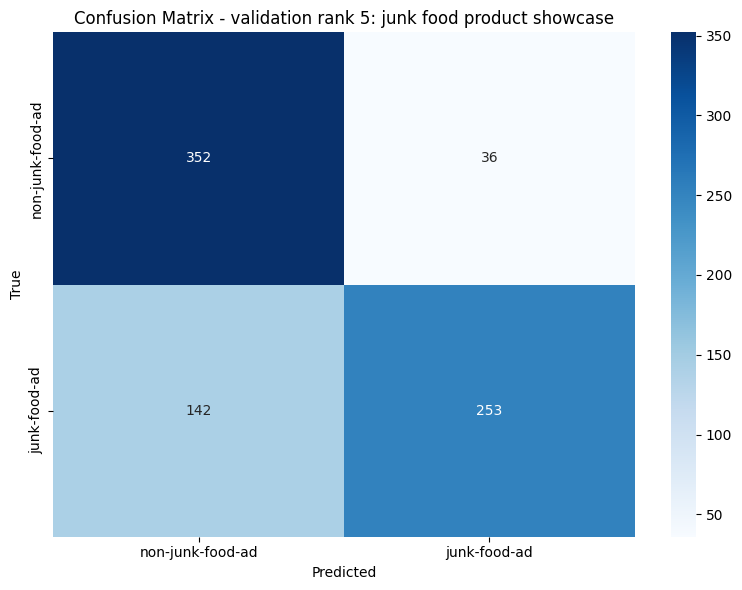


TEST SET METRICS - Validation rank 6 (SECONDARY)
Classes: ['junk food brand promotion', 'non-junk food content']
Validation F1: 74.54%
Accuracy: 75.22%
Precision: 78.47% (junk-food-ad)
Recall: 70.13% (junk-food-ad)
F1-Score: 74.06% (junk-food-ad)
Test images: 783 (negative: 388, positive: 395)
TN=312, FP=76, FN=118, TP=277
Evaluation time: 17.97 s
Confusion Matrix: [[312  76]
 [118 277]]


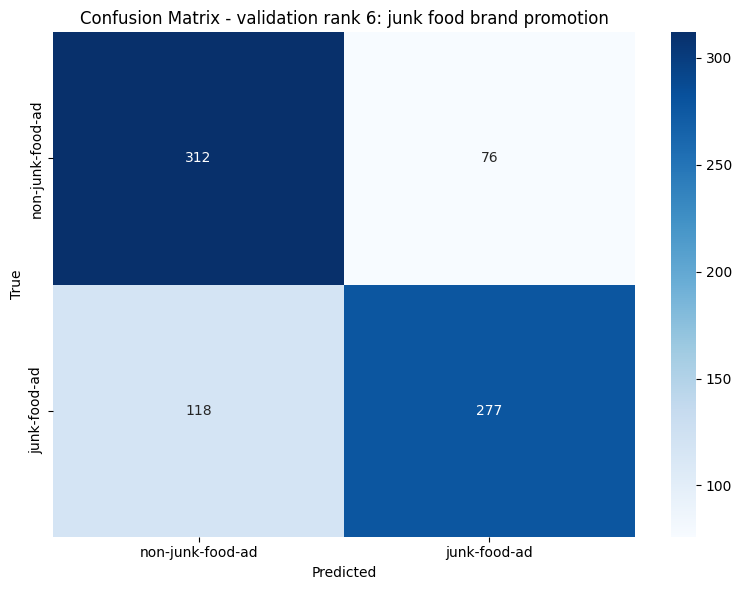


TEST SET METRICS - Validation rank 7 (SECONDARY)
Classes: ['picture showing fast food promotion', 'picture not showing fast food']
Validation F1: 73.52%
Accuracy: 78.03%
Precision: 87.54% (junk-food-ad)
Recall: 65.82% (junk-food-ad)
F1-Score: 75.14% (junk-food-ad)
Test images: 783 (negative: 388, positive: 395)
TN=351, FP=37, FN=135, TP=260
Evaluation time: 18.96 s
Confusion Matrix: [[351  37]
 [135 260]]


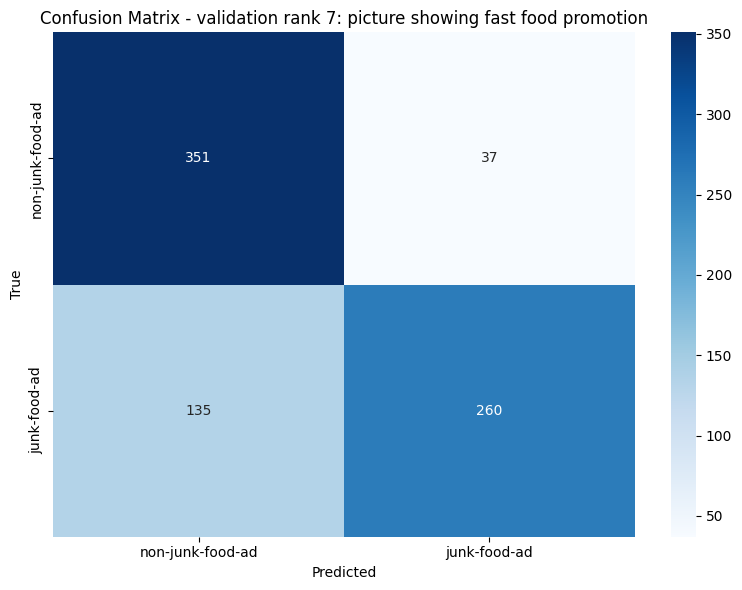


TEST SET METRICS - Validation rank 8 (SECONDARY)
Classes: ['marketing image centered on fast food meals', 'marketing image centered on other themes']
Validation F1: 73.48%
Accuracy: 77.78%
Precision: 86.47% (junk-food-ad)
Recall: 66.33% (junk-food-ad)
F1-Score: 75.07% (junk-food-ad)
Test images: 783 (negative: 388, positive: 395)
TN=347, FP=41, FN=133, TP=262
Evaluation time: 18.06 s
Confusion Matrix: [[347  41]
 [133 262]]


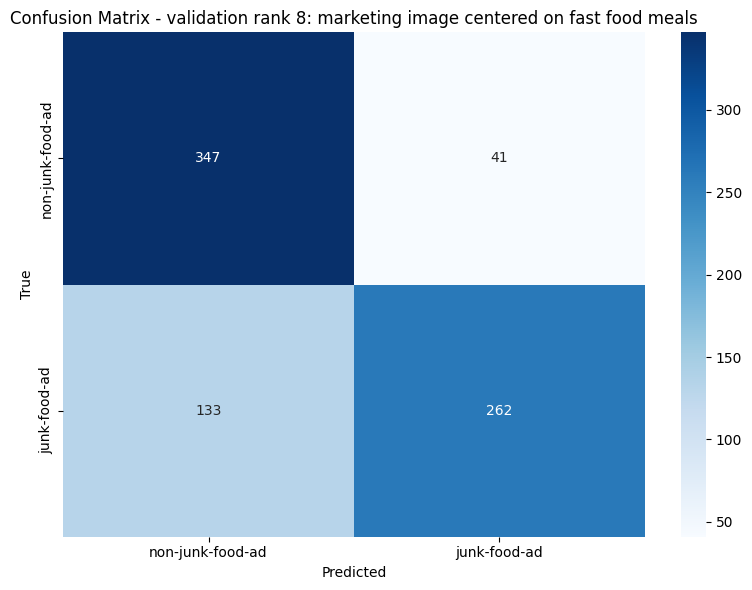


TEST SET METRICS - Validation rank 9 (SECONDARY)
Classes: ['carbonated sugary drink', 'plain water or tea']
Validation F1: 73.11%
Accuracy: 62.96%
Precision: 64.38% (junk-food-ad)
Recall: 59.49% (junk-food-ad)
F1-Score: 61.84% (junk-food-ad)
Test images: 783 (negative: 388, positive: 395)
TN=258, FP=130, FN=160, TP=235
Evaluation time: 17.99 s
Confusion Matrix: [[258 130]
 [160 235]]


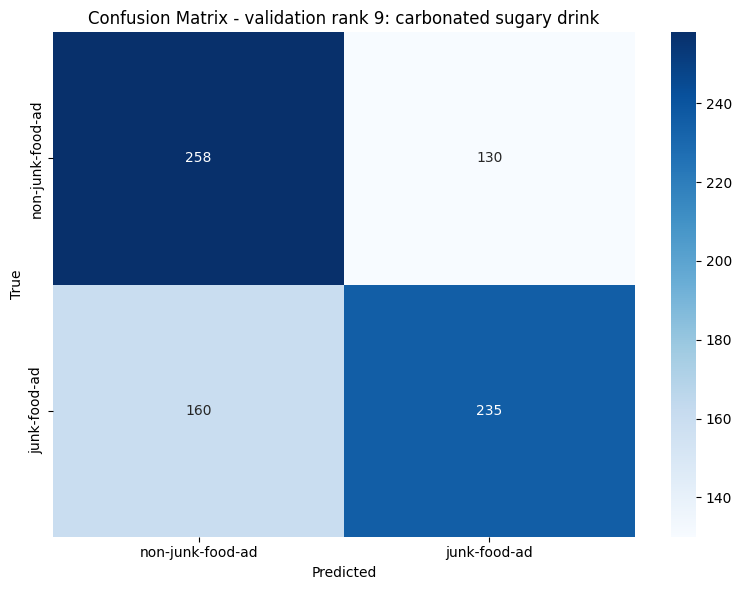


TEST SET METRICS - Validation rank 10 (SECONDARY)
Classes: ['processed food', 'whole food']
Validation F1: 72.83%
Accuracy: 55.81%
Precision: 54.13% (junk-food-ad)
Recall: 81.27% (junk-food-ad)
F1-Score: 64.98% (junk-food-ad)
Test images: 783 (negative: 388, positive: 395)
TN=116, FP=272, FN=74, TP=321
Evaluation time: 18.61 s
Confusion Matrix: [[116 272]
 [ 74 321]]


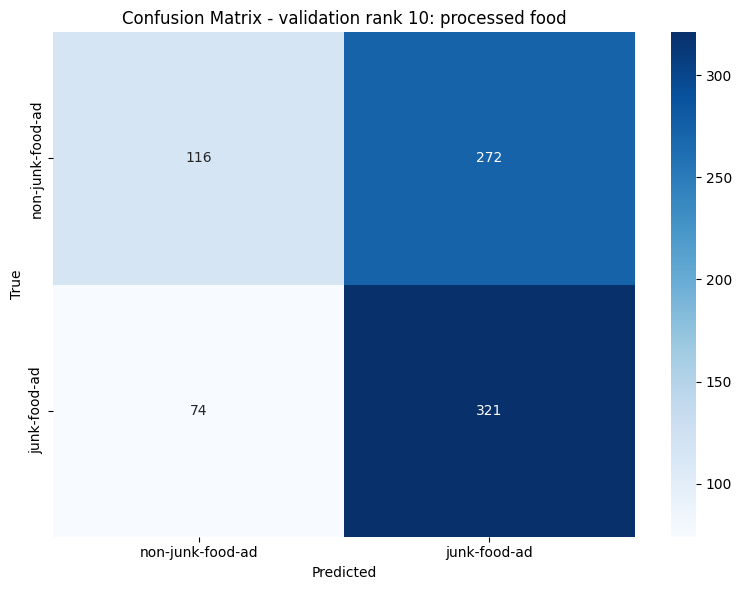

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Collect test results for the best 10 classes from validation
test_results_list = []
test_start = timed_now()

for i, result in enumerate(selected_results, 1):
    configuration_start = timed_now()
    results, ground_truth, image_paths = classify_images_with_clip(
        dataset_part="test", classes=result["classes"]
    )
    metrics = evaluate_predictions(
        image_paths=image_paths,
        ground_truth=ground_truth,
        results=results,
        class_true=result["classes"][0],
        class_false=result["classes"][1],
    )
    test_results_list.append({
        "validation_rank": i,
        "validation_f1": result["f1_score"],
        "classes": result["classes"],
        "metrics": metrics,
        "evaluation_seconds": timed_now() - configuration_start,
    })

test_seconds = timed_now() - test_start
primary_test_result = test_results_list[0]
print(f"Test evaluation (all ten configurations): {test_seconds:.2f} s")
print(f"Primary configuration evaluation: {primary_test_result['evaluation_seconds']:.2f} s")
print("CLIP training: none (pretrained weights remain frozen).")

for i, result in enumerate(test_results_list, 1):
    metrics = result["metrics"]
    class_name = result['classes'][0]

    print("\n" + "="*50)
    print(f"TEST SET METRICS - Validation rank {result['validation_rank']}" + (" (PRIMARY)" if i == 1 else " (SECONDARY)"))
    print(f"Classes: {result['classes']}")
    print(f"Validation F1: {result['validation_f1']:.2%}")
    print("="*50)
    print(f"Accuracy: {metrics['accuracy']:.2%}")
    print(f"Precision: {metrics['precision']:.2%} ({POSITIVE_CLASS})")
    print(f"Recall: {metrics['recall']:.2%} ({POSITIVE_CLASS})")
    print(f"F1-Score: {metrics['f1_score']:.2%} ({POSITIVE_CLASS})")
    tn, fp, fn, tp = metrics['confusion_matrix'].ravel()
    print(f"Test images: {tn + fp + fn + tp} (negative: {tn + fp}, positive: {fn + tp})")
    print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    print(f"Evaluation time: {result['evaluation_seconds']:.2f} s")
    print("Confusion Matrix:", metrics['confusion_matrix'])

    # Plot confusion matrix
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        metrics['confusion_matrix'],
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=[NEGATIVE_CLASS, POSITIVE_CLASS],
        yticklabels=[NEGATIVE_CLASS, POSITIVE_CLASS]
    )
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Confusion Matrix - validation rank {i}: {class_name}')
    plt.tight_layout()
    plt.show()

## Real images test

Display a reproducible random sample from both test classes using the primary configuration selected on validation and the same five-template ensemble. Cosine similarities are scores, not calibrated probabilities or confidence estimates.

Image 1/6: /content/binary_dataset/ad/2024-04-28_canal_7_processed_40720_6.jpg


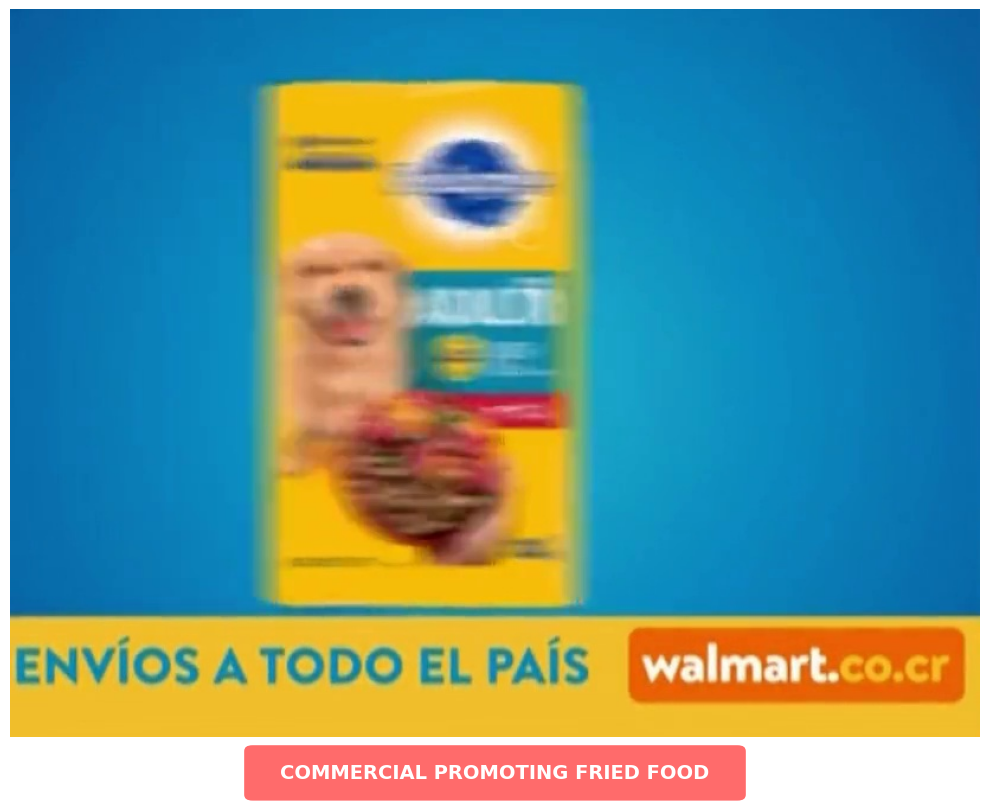

Prediction: commercial promoting fried food
True label: junk-food-ad
Correct: True
Cosine similarities (not probabilities):
  commercial promoting fried food: 0.2244
  commercial not promoting fried food: 0.2058
Image 2/6: /content/binary_dataset/ad/2024-05-21_canal_6_processed_31319_19.jpg


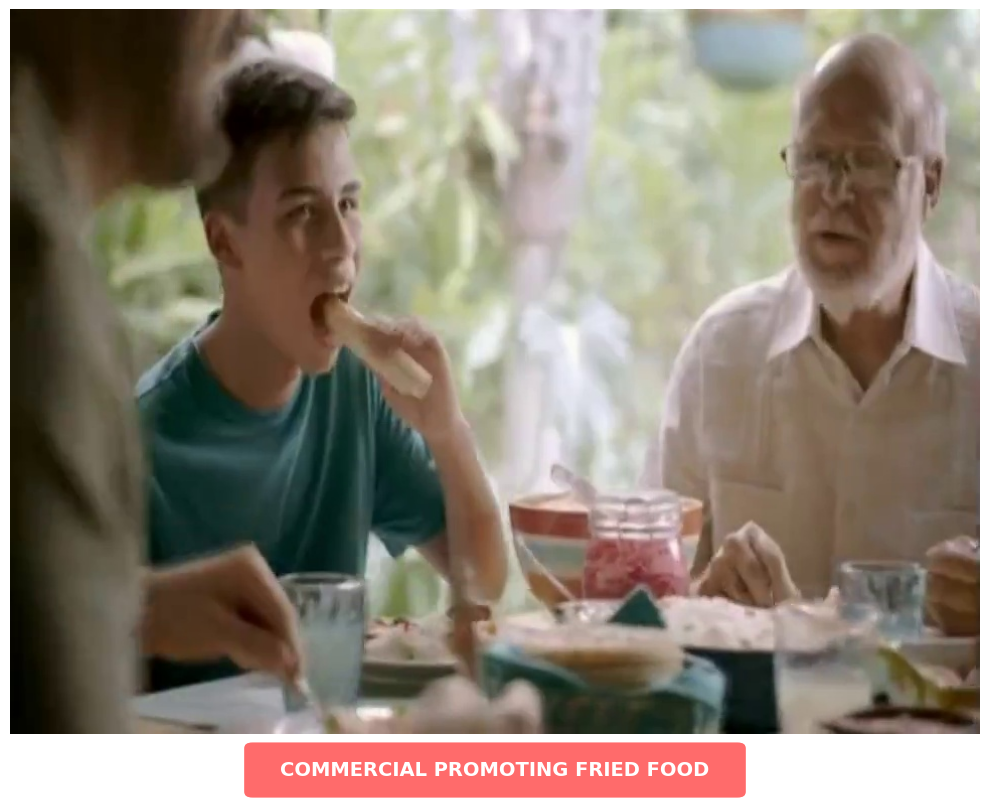

Prediction: commercial promoting fried food
True label: junk-food-ad
Correct: True
Cosine similarities (not probabilities):
  commercial promoting fried food: 0.2163
  commercial not promoting fried food: 0.2119
Image 3/6: /content/binary_dataset/ad/2024-05-21_canal_6_processed_31447_7.jpg


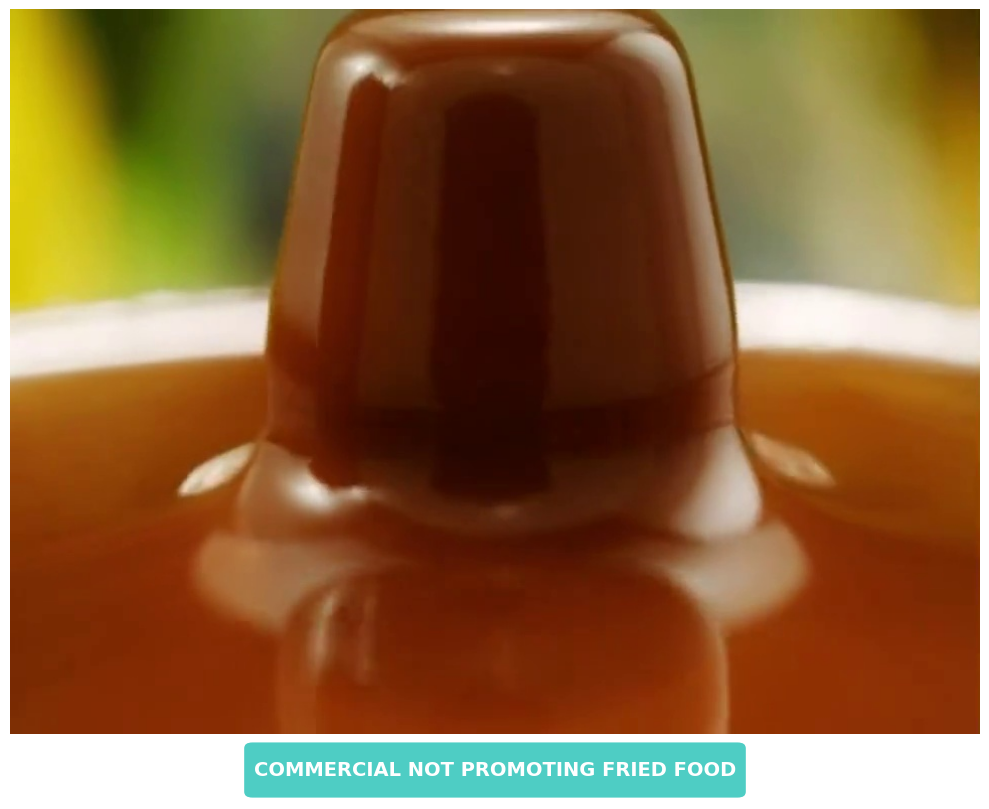

Prediction: commercial not promoting fried food
True label: junk-food-ad
Correct: False
Cosine similarities (not probabilities):
  commercial promoting fried food: 0.1278
  commercial not promoting fried food: 0.1290
Image 4/6: /content/binary_dataset/non_ad/2024-04-28_canal_6_non_ad_13714.jpg


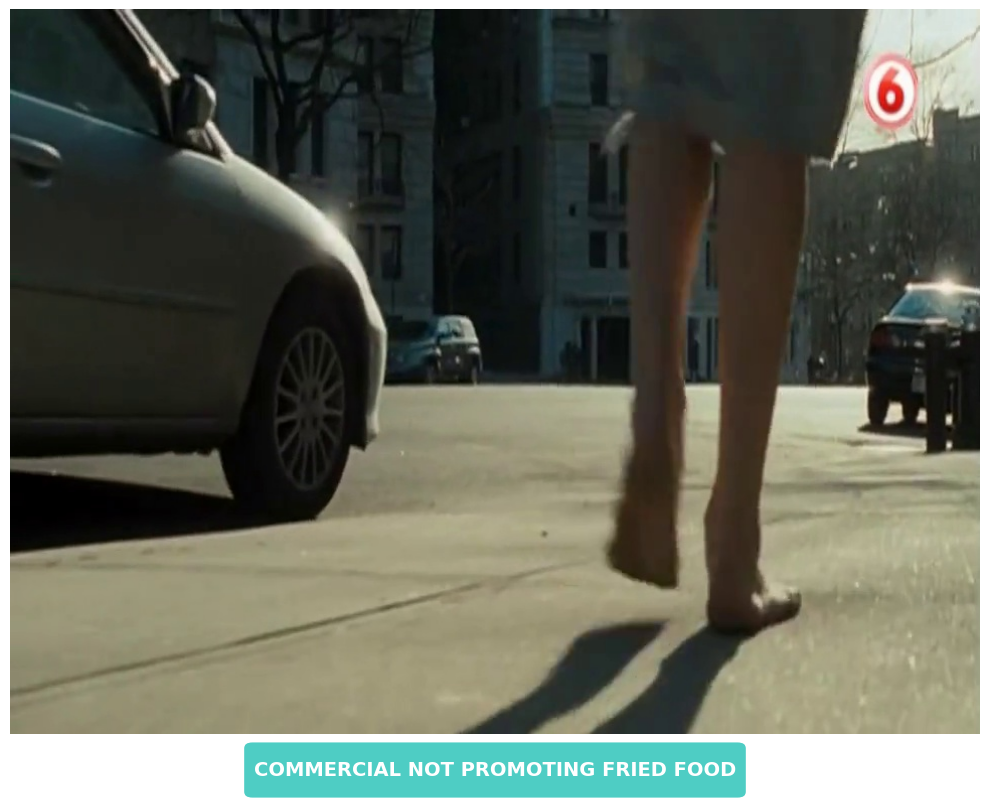

Prediction: commercial not promoting fried food
True label: non-junk-food-ad
Correct: True
Cosine similarities (not probabilities):
  commercial promoting fried food: 0.1452
  commercial not promoting fried food: 0.1520
Image 5/6: /content/binary_dataset/non_ad/2024-04-28_canal_6_non_ad_13458.jpg


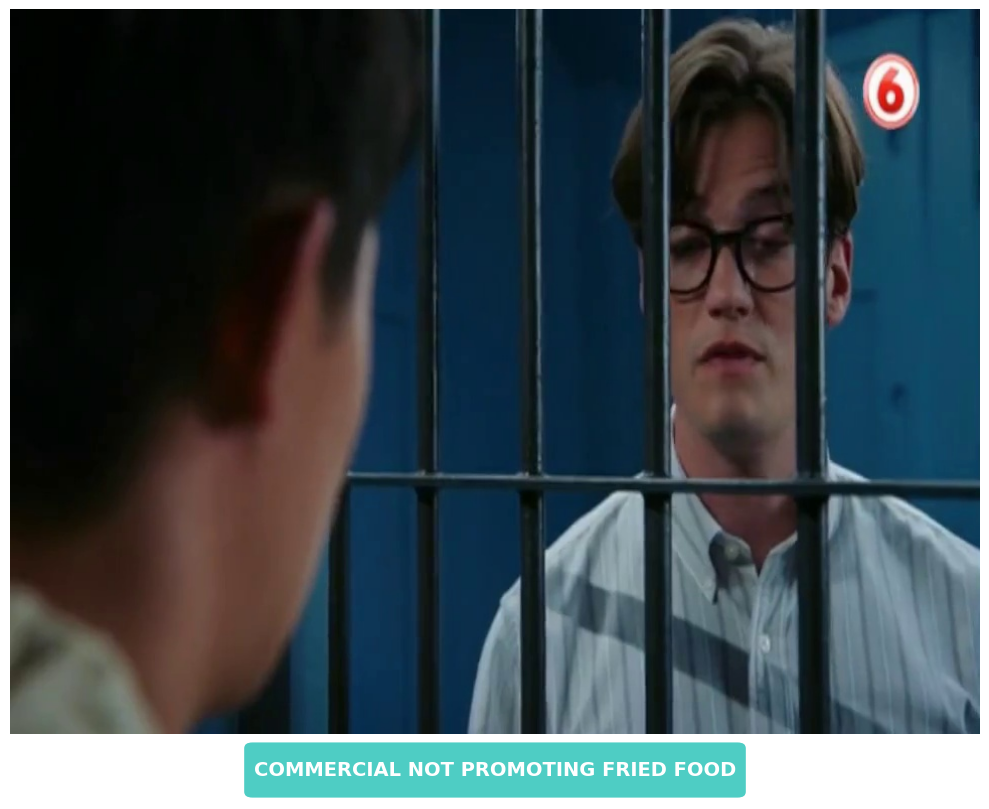

Prediction: commercial not promoting fried food
True label: non-junk-food-ad
Correct: True
Cosine similarities (not probabilities):
  commercial promoting fried food: 0.0966
  commercial not promoting fried food: 0.1132
Image 6/6: /content/binary_dataset/non_ad/2024-05-15_canal_6_non_ad_20920.jpg


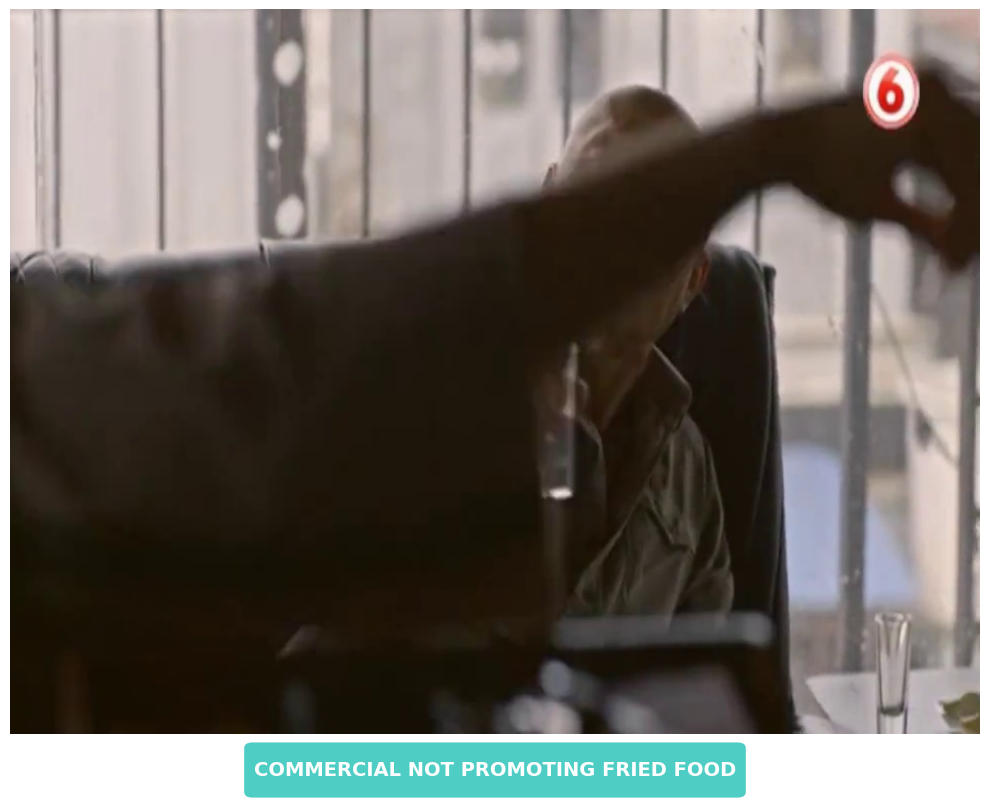

Prediction: commercial not promoting fried food
True label: non-junk-food-ad
Correct: True
Cosine similarities (not probabilities):
  commercial promoting fried food: 0.1321
  commercial not promoting fried food: 0.1365


In [10]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

best_classes = primary_test_result["classes"]

# Map each test image path to its true class
test_labels = {path: class_name for path, class_name in splits_data["test"]}

example_rng = random.Random(SEED)
random_images = []
for class_name in (POSITIVE_CLASS, NEGATIVE_CLASS):
    candidates = [path for path, label in splits_data["test"] if label == class_name]
    random_images.extend(example_rng.sample(candidates, min(3, len(candidates))))

text_features = encode_class_prompts(best_classes)

# Define colors for labels
colors = {
    best_classes[0]: "#FF6B6B",       # Red
    best_classes[1]: "#4ECDC4"        # Teal
}

for idx, random_image_path in enumerate(random_images, 1):
    print(f"{'='*60}")
    print(f"Image {idx}/{len(random_images)}: {random_image_path}")
    print('='*60)

    # Load and preprocess the image
    with Image.open(random_image_path) as source_image:
        image = source_image.convert("RGB")
    image_input = preprocess(image).unsqueeze(0).to(device)

    # Run inference
    with torch.no_grad():
        image_features = model.encode_image(image_input)

        image_features = image_features / image_features.norm(dim=-1, keepdim=True)

        similarities = (image_features @ text_features.T)[0].cpu().numpy()

    # Get prediction
    predicted_idx = similarities.argmax()
    predicted_class = best_classes[predicted_idx]

    # Determine if junk food ad
    is_junk_food = predicted_idx == 0

    # Get true label from the split mapping
    true_is_junk_food = test_labels[random_image_path] == POSITIVE_CLASS
    is_correct = is_junk_food == true_is_junk_food

    # Display the image with prediction
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    ax.imshow(image)
    ax.axis("off")

    # Create label badge
    label_color = colors.get(predicted_class, "#95A5A6")
    label_text = predicted_class.upper()

    # Add colored badge at the bottom
    badge = mpatches.FancyBboxPatch(
        (0.25, -0.08), 0.5, 0.06,
        boxstyle="round,pad=0.01",
        facecolor=label_color,
        edgecolor="white",
        linewidth=2,
        transform=ax.transAxes,
        clip_on=False
    )
    ax.add_patch(badge)
    ax.text(
        0.5, -0.05,
        label_text,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        color="white",
        ha="center",
        va="center"
    )

    plt.tight_layout()
    plt.show()

    true_label_text = "junk-food-ad" if true_is_junk_food else "non-junk-food-ad"
    print(f"Prediction: {predicted_class}")
    print(f"True label: {true_label_text}")
    print(f"Correct: {is_correct}")
    print("Cosine similarities (not probabilities):")
    for cls, score in zip(best_classes, similarities):
        print(f"  {cls}: {score:.4f}")